In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
url='/content/modified_placement_data.csv'
df=pd.read_csv(url)

In [ ]:
df.head(5)

,cgpa,iq,placement
0,"6,8",123.0,Yes
1,"5,9",106.0,No
2,"5,3",121.0,No
3,"7,4",132.0,Yes
4,"5,8",142.0,No


In [ ]:
df.isnull().sum()

,0
cgpa,5
iq,0
placement,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   cgpa       95 non-null     object 
 1   iq         100 non-null    float64
 2   placement  100 non-null    object 
dtypes: float64(1), object(2)
memory usage: 2.5+ KB


In [ ]:
df['cgpa'] = df['cgpa'].str.replace(",", ".")

In [ ]:
df['cgpa']

,cgpa
0,6.8
1,5.9
2,5.3
3,7.4
4,5.8
...,...
95,4.3
96,4.4
97,6.7
98,6.3


In [ ]:
df['cgpa'] = df['cgpa'].astype(float)
df['cgpa'] = df['cgpa'].fillna(df['cgpa'].mean())

In [ ]:
df.isnull().sum()

,0
cgpa,0
iq,0
placement,0


In [ ]:
df.head(4)

,cgpa,iq,placement
0,6.8,123.0,Yes
1,5.9,106.0,No
2,5.3,121.0,No
3,7.4,132.0,Yes


In [ ]:
df['placement'].unique()

array([1, 0])

In [ ]:
df['placement']=df['placement'].map({'Yes':1,'No':0})

In [ ]:
df.head(5)

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


In [ ]:
from sklearn.preprocessing import StandardScaler
ss=StandardScaler()
col=['cgpa','iq']
for i in col:
  df[i]=ss.fit_transform(df[[i]])


In [ ]:
df.head(2)

,cgpa,iq,placement
0,0.723422,-0.014593,1
1,-0.078816,-0.442331,0


<Axes: >

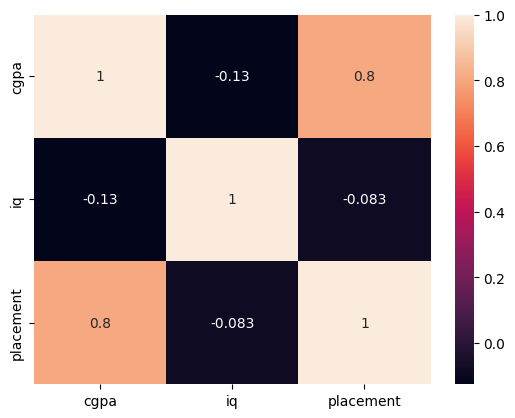

In [ ]:
sns.heatmap(df.corr(),annot=True)

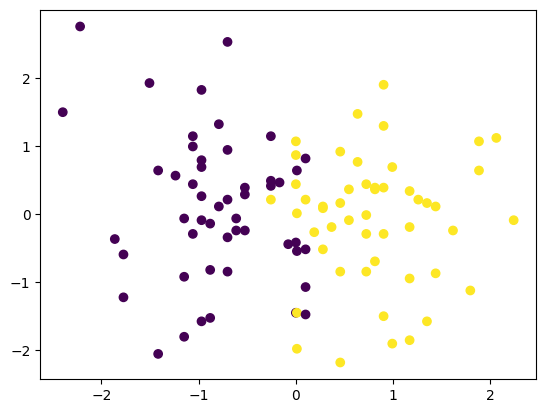

In [ ]:
plt.scatter(data=df,x='cgpa',y='iq',c=df['placement'])

In [ ]:
x=df.drop('placement',axis=1)
y=df['placement']

In [ ]:
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=.20,random_state=42)

In [ ]:
from sklearn.linear_model import LogisticRegression
lr=LogisticRegression()
lr.fit(xtrain,ytrain)

LogisticRegression()

In [ ]:
ypred=lr.predict(xtest)

In [ ]:
from sklearn.metrics import accuracy_score
accuracy_score(ytest,ypred)

0.85